In [114]:
import os

from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

# Load environment variables from the project's .env file.
load_dotenv()

# Initialize Gemini through LangChain.
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.3,
    max_retries=2
)

In [2]:
from collections import defaultdict, deque
from typing import Optional
from datetime import datetime

from pydantic import BaseModel, Field

from langchain_core.messages import (
    HumanMessage,
    AIMessage,
    SystemMessage
)

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.output_parsers import StrOutputParser
from langchain_core.documents import Document

In [3]:
session_store = defaultdict(list)

def chat(user_id, session_id, user_input):

    key = (user_id, session_id)

    history = session_store[key]

    messages = [
        SystemMessage(
            content="You are a helpful shopping assistant."
        ),
        *history,
        HumanMessage(content=user_input)
    ]

    response = llm.invoke(messages)

    history.append(HumanMessage(content=user_input))
    history.append(response)

    return response.content

In [4]:
print(
    chat(
        "USER101",
        "SESSION_A",
        "I am looking for a laptop under 70000."
    )
)

C:\Users\admin\.conda\envs\insurance_llm\Lib\site-packages\langchain_google_genai\chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'To help you find the best laptop under ₹70,000, I need a little more information about what you plan to use it for. \n\nCould you please let me know:\n\n1. **What is your primary use?** (e.g., Gaming, Coding, Video Editing, Office work/Studies, or General everyday use)\n2. **Do you have brand preferences?** (e.g., HP, Lenovo, Dell, ASUS, Acer, MacBook)\n3. **Are portability and battery life important to you?** (Do you want something lightweight to carry around, or will it mostly stay on a desk?)\n4. **Do you need Windows or macOS?** (MacBook Air M1 sometimes drops close to this price during sales).\n\nOnce you share these details, I can give you 3-4 specific recommendations tailored just for you!', 'extras': {'signature': 'EpYBCpMBAWkUfRO9cDYwX4c8RbtDElHAD5F8V11DRdD6Oh/eOa6tlLrfVDxBCzELiagoT2/geDW6qH8XhKhmZsAKPHgSASUWpwPMmxxjfLTAehkZwV79uJ4i6PnJ7IsvKAqxzFmtpCT0RE+SQQP0CUuywYOdL9M5GRk4Pta165xw7KFRmy2NvpFRNrOA8MgJB+3VR+pV2tKb'}}]


In [5]:

print(
    chat(
        "USER101",
        "SESSION_A",
        "I prefer Windows."
    )
)

[{'type': 'text', 'text': 'Thanks for specifying Windows! With a budget of under ₹70,000, you are in a fantastic "sweet spot." You can get a powerful processor (like Intel Core i5/i7 12th/13th Gen or AMD Ryzen 5/7), dedicated graphics for light gaming and editing, or a very premium, lightweight laptop for productivity.\n\nHere are the top Windows laptop recommendations under ₹70,000 based on different needs:\n\n---\n\n### 1. Best for Gaming & Heavy Tasks (Video Editing / Coding)\n**Lenovo IdeaPad Gaming 3** or **ASUS TUF Gaming F15**\n* **Price:** Usually around ₹60,000 - ₹68,000 (depending on sales)\n* **Key Specs:** \n  * Processor: AMD Ryzen 5 6600H or Intel Core i5 (12th Gen)\n  * Graphics: NVIDIA RTX 3050 or RTX 2050 (4GB)\n  * RAM/Storage: 16GB RAM / 512GB SSD\n  * Display: 15.6-inch FHD, 120Hz/144Hz refresh rate\n* **Why buy:** If you want to play modern games, do 4K video editing, or heavy programming, gaming laptops offer the best raw performance for the price. The cooling sys

In [8]:
print(
    chat(
        "USER101",
        "SESSION_A",
        "What was my laptop budget?"
    )
)

[{'type': 'text', 'text': 'Your laptop budget is **under ₹70,000**.', 'extras': {'signature': 'EpYBCpMBAWkUfROz1MvaNKxjiZMRTFcuuAYhLiAgs0Q4Dy9vKuzeQpAO7c3n/pbHAuM2LPfrvm4kLH2M1tAUBkPwpHtp8zVaFqKKi7qnWBDOUWKdBJmJ3xT+BhBGjYSU7A1pzkhQTtOqsR4A7pOzgiXz0n5HqanvHDL+4AvkyTErkKfn8LRyW7wMMEiKElRxDEi9Awit7rF7'}}]


In [6]:
print(
    chat(
        "USER202",
        "SESSION_B",
        "What was my laptop budget?"
    )
)

[{'type': 'text', 'text': "I don't have access to your personal information or past conversations, so I don't know your laptop budget. \n\nIf you'd like, you can tell me your budget now, and I can help you find some great laptop options!", 'extras': {'signature': 'EpYBCpMBAWkUfRPsFpxNbdI73oGrYZBWuMuWmaYatBnfOyjLAbSdFiUvulpVOniP7OmAdxtLM13IxTTQ2MISS/o23DlLpViru/Wc8XxTB39aC0Swxk7ghqZLKIkvGp0wxOp/9fJ4qGNGRwrix8DuLCRmLXSjpKUw6jfJA9L4a6hZuvmoQbavm0u0HPz0NgeVBP6zJTvWHP4q'}}]


In [27]:
session_store[('USER101', 'SESSION_A')][1]

AIMessage(content=[{'type': 'text', 'text': 'To help you find the best laptop under ₹70,000, I need a little more information about what you plan to use it for. \n\nCould you please let me know:\n\n1. **What is your primary use?** (e.g., Gaming, Coding, Video Editing, Office work/Studies, or General everyday use)\n2. **Do you have brand preferences?** (e.g., HP, Lenovo, Dell, ASUS, Acer, MacBook)\n3. **Are portability and battery life important to you?** (Do you want something lightweight to carry around, or will it mostly stay on a desk?)\n4. **Do you need Windows or macOS?** (MacBook Air M1 sometimes drops close to this price during sales).\n\nOnce you share these details, I can give you 3-4 specific recommendations tailored just for you!', 'extras': {'signature': 'EpYBCpMBAWkUfRO9cDYwX4c8RbtDElHAD5F8V11DRdD6Oh/eOa6tlLrfVDxBCzELiagoT2/geDW6qH8XhKhmZsAKPHgSASUWpwPMmxxjfLTAehkZwV79uJ4i6PnJ7IsvKAqxzFmtpCT0RE+SQQP0CUuywYOdL9M5GRk4Pta165xw7KFRmy2NvpFRNrOA8MgJB+3VR+pV2tKb'}}], additional_k

In [36]:
from collections import defaultdict

# Simulated persistent store for demonstration.
database = defaultdict(list)


def load_history(user_id, session_id):

    key = (user_id, session_id)

    return database[key]


def save_messages(user_id, session_id, messages):

    key = (user_id, session_id)

    database[key].extend(messages)


def insurance_chat(user_id, session_id, question):

    history = load_history(user_id, session_id)

    messages = [
        SystemMessage(
            content="""
            You are an insurance support assistant.
            Answer based on the available conversation.
            Do not invent claim status or policy coverage.
            """
        ),
        *history,
        HumanMessage(content=question)
    ]

    response = llm.invoke(messages)

    save_messages(
        user_id,
        session_id,
        [
            HumanMessage(content=question),
            response
        ]
    )

    return response.content

In [37]:
answer1 = insurance_chat(
    user_id="U101",
    session_id="S001",
    question="My claim number is CLM501."
)

print(answer1)

C:\Users\admin\.conda\envs\insurance_llm\Lib\site-packages\langchain_google_genai\chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Thank you for providing your claim number, CLM501. How can I assist you with this claim today?', 'extras': {'signature': 'EpYBCpMBAWkUfROIrIdy1Kh2vIhhC+uny9jUz82mQ/Wa2ep76hygbuTLAWvCk5HZgXhfpk17UuNJfUQhaqOEpRfSUVlG4JQ3y8HWtlwqmK2n8E5TZhGeuI6UQemAowgKTtHcalsE/WNzTPOHcc4FO5zI2aEg5S8aSkScc7RD15RUmAbDfn0c1TB4ck1nN09mJzfXFcxi2kmS'}}]


In [38]:
answer2 = insurance_chat(
    user_id="U101",
    session_id="S001",
    question="What was my claim number?"
)

print(answer2)

[{'type': 'text', 'text': 'Your claim number is CLM501.', 'extras': {'signature': 'EpYBCpMBAWkUfRPuRqzGY3j0emIZYb3CUIyabRtZddg+AEUHcOxw87vVUxlz8+lXSMCVK1JOvll4iUUngYcvgNV1bRNlYGCAonlM7bLxX/CNlos6+/6sYm3eMY+9MRHd3rN7qONsdowQ5R3xSnLKCLFPNuD5bFKC9t+AU8rB5/pXi7YCjQMHPmMziBxhoLbjxVTCeMpRYFZ1'}}]


Here, load_history() and save_messages() are application functions backed by a persistent database.

A possible database structure:
user_id	session_id	role	message	created_at
U101	S001	human	My claim is CLM501	Timestamp
U101	S001	ai	How can I help?	Timestamp
U101	S001	human	It is still pending	Timestamp

Production considerations:
- Authenticate the user before accepting their user_id.
- Don't trust a customer-supplied ID to access someone else's history.
- Use a database rather than a process-local dictionary.
- Consider expiration and retention policies for sensitive conversation data.
- Use a transaction or suitable concurrency controls when saving messages.
When to use: Almost every conversational application needs this foundation.

In [39]:
for key, messages in database.items():

    print("\nConversation:", key)

    for message in messages:
        print(message.type, ":", message.content)


Conversation: ('U101', 'S001')
human : My claim number is CLM501.
ai : [{'type': 'text', 'text': 'Thank you for providing your claim number, CLM501. How can I assist you with this claim today?', 'extras': {'signature': 'EpYBCpMBAWkUfROIrIdy1Kh2vIhhC+uny9jUz82mQ/Wa2ep76hygbuTLAWvCk5HZgXhfpk17UuNJfUQhaqOEpRfSUVlG4JQ3y8HWtlwqmK2n8E5TZhGeuI6UQemAowgKTtHcalsE/WNzTPOHcc4FO5zI2aEg5S8aSkScc7RD15RUmAbDfn0c1TB4ck1nN09mJzfXFcxi2kmS'}}]
human : What was my claim number?
ai : [{'type': 'text', 'text': 'Your claim number is CLM501.', 'extras': {'signature': 'EpYBCpMBAWkUfRPuRqzGY3j0emIZYb3CUIyabRtZddg+AEUHcOxw87vVUxlz8+lXSMCVK1JOvll4iUUngYcvgNV1bRNlYGCAonlM7bLxX/CNlos6+/6sYm3eMY+9MRHd3rN7qONsdowQ5R3xSnLKCLFPNuD5bFKC9t+AU8rB5/pXi7YCjQMHPmMziBxhoLbjxVTCeMpRYFZ1'}}]


Memory 2 — Window memory

Requirement: Retain only the last two complete conversational exchanges.

In [50]:
conversation_history = deque(maxlen=4)
def chat(user_input):

    messages = [
        SystemMessage(
            content="You are a helpful shopping assistant."
        ),
        *conversation_history,
        HumanMessage(content=user_input)
    ]
    print("\n--- MESSAGES SENT TO GEMINI ---")

    for message in messages:
        print(message.type, ":", message.content)
    
    response = llm.invoke(messages)

    conversation_history.append(
        HumanMessage(content=user_input)
    )

    conversation_history.append(response)
    print("\n--- STORED WINDOW ---")

    for message in conversation_history:
        print(message.type, ":", message.content)
    print("Total messages:", len(conversation_history))
    return response.content

In [51]:
print(chat("I need a laptop."))
print(chat("My budget is ₹70,000."))
print(chat("I prefer Windows."))
print(chat("I will use it for programming."))
print(chat("Suggest a suitable brand."))


--- MESSAGES SENT TO GEMINI ---
system : You are a helpful shopping assistant.
human : I need a laptop.

--- STORED WINDOW ---
human : I need a laptop.
ai : [{'type': 'text', 'text': "I'd love to help you find the right laptop! To get started, could you tell me a little bit about what you plan to use it for? \n\nHere are a few quick questions to help narrow it down:\n1. **What is your budget?** \n2. **What will you be using it for?** (e.g., everyday web browsing and Netflix, heavy gaming, video editing, programming, or school/work?)\n3. **Do you have a preferred operating system?** (Windows, Apple macOS, or Chromebook/ChromeOS?)\n4. **Do you care about portability?** (Do you need something super light to carry around all day, or will it mostly stay on a desk?)\n\nOnce I have a better idea of your needs, I can give you a few specific recommendations!", 'extras': {'signature': 'EpYBCpMBAWkUfRMNILpTVOGV4eX3XClmE6+T3u/v/tWzPHsonyJ8QrVpRvIfvvcf/i6kxWXkKBHNHAHUihnRrpjDvpGUZecQ7CiM1BZVMqw50V

In [47]:
print(chat("What was my original laptop budget?"))

[{'type': 'text', 'text': 'Your original laptop budget was **₹70,000**.', 'extras': {'signature': 'EpYBCpMBAWkUfRPPxh8WYQT62p70U6ygYM8P8egnsJqPwTn4VhVRRO78z2VCpIqSr5ioXHJ/ieOQdEVV3XLcZOnRaewdS0p2y0zCFA8rULCthtRjMTXxl3hoKTPdQQnDzJJN31Z5fzfUGFQfRT9nbimi6B27tOCEBclbe5lrBO4iNwy9F8rC4475JgVXxtD17Hk0X3eiU8e3'}}]


In [ ]:
# 2. Store conversation windows

# Each user/session combination gets its own deque.
session_histories = defaultdict(
    lambda: deque(maxlen=6)
)


# 3. Define the application function

def insurance_chat(user_id, session_id, question):

    # Create a unique key for this conversation.
    session_key = (user_id, session_id)

    # Retrieve the existing window.
    history = session_histories[session_key]

    # Construct the messages for this invocation.
    messages = [
        SystemMessage(
            content="""
            You are an insurance support assistant.

            Use the supplied conversation history
            to understand follow-up questions.

            Never invent claim status or policy coverage.
            """
        ),
        *history,
        HumanMessage(content=question)
    ]

    # Invoke Gemini.
    response = llm.invoke(messages)

    # Store the new exchange.
    history.append(
        HumanMessage(content=question)
    )

    history.append(response)

    return response.content


# 4. Execute the application

print(
    insurance_chat(
        user_id="U101",
        session_id="S001",
        question="My claim number is CLM501."
    )
)

print(
    insurance_chat(
        user_id="U101",
        session_id="S001",
        question="I submitted my hospital bills yesterday."
    )
)

print(
    insurance_chat(
        user_id="U101",
        session_id="S001",
        question="How long will it take to process my claim?"
    )
)

print(
    insurance_chat(
        user_id="U202",
        session_id="S002",
        question="What is my claim number?"
    )
)

Summary Memory

In [54]:
conversation_history = []

conversation_summary = ""

In [56]:
response_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        You are an insurance support assistant.

        Previous conversation summary:
        {summary}

        Use the summary and conversation history
        to understand the customer.

        Never invent claim status or policy coverage.
        """
    ),
    MessagesPlaceholder("history"),
    ("human", "{question}")
])

response_chain = response_prompt | llm | StrOutputParser()

In [57]:
summary_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        Summarise the customer conversation.

        Preserve:
        - Policy and claim numbers
        - Documents submitted
        - Customer concerns
        - Important decisions
        - Unresolved questions

        Do not invent information.
        """
    ),
    (
        "human",
        """
        Existing summary:
        {old_summary}

        New conversation:
        {new_messages}

        Generate an updated summary.
        """
    )
])

summary_chain = summary_prompt | llm | StrOutputParser()


In [58]:
def chat(user_input):

    global conversation_summary

    # Generate response using existing history and summary.
    response = response_chain.invoke({
        "summary": conversation_summary or "No previous summary.",
        "history": conversation_history,
        "question": user_input
    })

    # Add the new exchange to history.
    conversation_history.append(
        HumanMessage(content=user_input)
    )

    conversation_history.append(
        AIMessage(content=response)
    )

    # Trigger summary after 3 exchanges.
    if len(conversation_history) >= 6:

        conversation_text = "\n".join(
            f"{message.type}: {message.content}"
            for message in conversation_history
        )

        conversation_summary = summary_chain.invoke({
            "old_summary": conversation_summary or "No previous summary.",
            "new_messages": conversation_text
        })

        print("\n--- UPDATED CONVERSATION SUMMARY ---")
        print(conversation_summary)

        # Clear messages already incorporated into summary.
        conversation_history.clear()

    return response

In [59]:
print(chat(
    "My policy number is POL1025."
))

Thank you for providing your policy number, POL1025. 

How can I assist you with your policy today?


In [60]:
print(chat(
    "I submitted a hospitalisation claim with number CLM501."
))

Thank you for providing your claim number, CLM501, along with your policy number, POL1025. 

To help you with your hospitalisation claim, what specific information or assistance do you need today? (For example, would you like to check the current status of the claim, or do you have questions about the required documents?)


In [61]:
print(chat(
    "I submitted my discharge summary and hospital bills yesterday."
))


--- UPDATED CONVERSATION SUMMARY ---
**Policy and Claim Numbers:**
- Policy Number: POL1025
- Claim Number: CLM501 (Hospitalisation claim)

**Documents Submitted:**
- Discharge summary (submitted yesterday)
- Hospital bills (submitted yesterday)

**Customer Concerns:**
- Customer inquired about/noted the submission of their hospitalisation claim documents.

**Important Decisions:**
- None.

**Unresolved Questions:**
- None.
Thank you for letting me know that you submitted your discharge summary and hospital bills yesterday for claim CLM501 under policy POL1025. 

To ensure I give you the most accurate update, I don't have direct access to real-time processing statuses in this chat, but I can note that your documents were submitted. Generally, claims processing can take a few business days as our team reviews the new documents. 

Is there anything specific regarding the review process or your coverage that I can help answer for you?


In [62]:
print(chat(
    "How long will it take to process my claim?"
))

print(chat(
    "Do I need to submit any additional documents?"
))

I understand you'd like to know the processing time for your hospitalisation claim (Claim Number: CLM501 under Policy POL1025), especially since you just submitted your discharge summary and hospital bills yesterday. 

While I don't have the exact timeframe for your specific claim in front of me right now, standard processing times can vary based on the details of the claim and the documents provided. 

Would you like me to check the current status of your claim with our processing team and get back to you with an estimated timeframe?
I can see from our records that you submitted your discharge summary and hospital bills yesterday for claim CLM501 under policy POL1025. 

However, whether any additional documents are needed depends on the specific requirements of your claim and what our claims team finds upon reviewing the discharge summary and bills. 

Would you like me to check with the processing team to see if they require anything further from you at this stage?


Entity Memory

In [75]:
from typing import Optional

from pydantic import BaseModel, Field


In [85]:
from typing import Optional
from pydantic import BaseModel, Field


class Entity(BaseModel):
    name: str = Field(
        description="Name or identifier of the entity"
    )

    entity_type: str = Field(
        description="Type of entity, such as Person, Vehicle, Company, Product, Place, Policy"
    )

    attributes: dict[str, str] = Field(
        default_factory=dict,
        description="Relevant attributes associated with this entity"
    )


class EntityExtraction(BaseModel):
    entities: list[Entity] = Field(
        default_factory=list,
        description="All entities and their relevant attributes extracted from the input"
    )

In [91]:
extraction_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        Extract all meaningful entities and their attributes
        from the user's message.

        Entities may include people, organisations, products,
        vehicles, locations, accounts, policies, claims,
        events, and other relevant concepts.

        For every entity:
        - Identify its name.
        - Identify its entity type.
        - Extract relevant attributes explicitly mentioned.
        - Do not invent missing information.
        - Avoid creating duplicate entities.
        - If an entity is mentioned without sufficient identifying
          information, retain only what is known.
        """
    ),
    ("human", "{user_input}")
])

In [93]:
structured_llm = llm.with_structured_output(
    EntityExtraction
)

extraction_chain = extraction_prompt | structured_llm

In [94]:
def extract_entities(user_input):

    extracted_data = extraction_chain.invoke({
        "user_input": user_input
    })

    return extracted_data.model_dump()

In [81]:
facts = extract_entities(
    "My name is Rahul. I own a 2022 Honda City."
)

print(facts)
print(type(facts))

{'person_name': 'Rahul', 'vehicle_make': 'Honda', 'vehicle_model': 'City', 'vehicle_year': 2022}
<class 'dict'>


In [95]:
facts = extract_entities(
    "My name is Rahul. I own a 2022 Honda City."
)
print(facts)

{'entities': [{'name': 'Rahul', 'entity_type': 'Person', 'attributes': {}}, {'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda', 'model': 'City'}}]}


In [ ]:
facts = extract_entities(
    "I purchased an iPhone 17 Pro from Amazon for ₹1,20,000."
)

In [ ]:
facts = extract_entities(
    "My father Rajesh is consulting Dr. Sharma at Apollo Hospital."
)

Entity Memory — Part 2: Storage, association and updates

Create an entity memory store
For our initial implementation, let's use a Python dictionary.

In [97]:
entity_memory = {}

In [98]:
def store_entities(extracted_data):

    for entity in extracted_data["entities"]:

        entity_name = entity["name"]

        entity_key = entity_name.strip().lower()

        if entity_key not in entity_memory:

            entity_memory[entity_key] = {
                "name": entity_name,
                "entity_type": entity["entity_type"],
                "attributes": {}
            }

        entity_memory[entity_key]["attributes"].update(
            entity["attributes"]
        )

In [99]:
def process_message(user_input):

    extracted_data = extract_entities(user_input)

    print("Extracted entities:")
    print(extracted_data)

    store_entities(extracted_data)

    print("\nUpdated entity memory:")
    print(entity_memory)

In [100]:
process_message(
    "My name is Rahul. I own a 2022 Honda City."
)

Extracted entities:
{'entities': [{'name': 'Rahul', 'entity_type': 'Person', 'attributes': {}}, {'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda'}}]}

Updated entity memory:
{'rahul': {'name': 'Rahul', 'entity_type': 'Person', 'attributes': {}}, 'honda city': {'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda'}}}


In [101]:
process_message(
    "My Honda City is white."
)

Extracted entities:
{'entities': [{'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'color': 'white'}}]}

Updated entity memory:
{'rahul': {'name': 'Rahul', 'entity_type': 'Person', 'attributes': {}}, 'honda city': {'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda', 'color': 'white'}}}


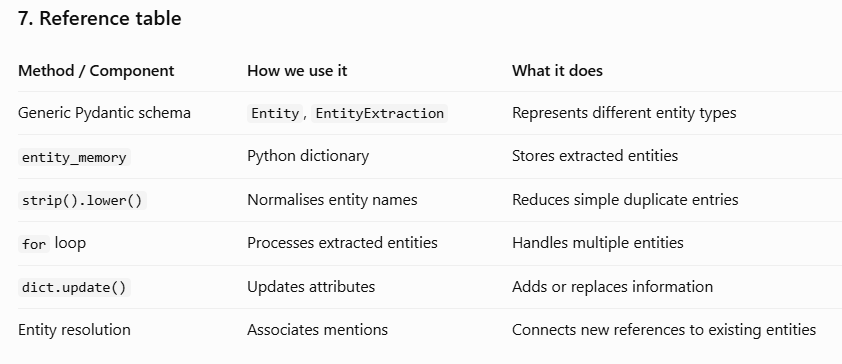

Entity Memory — Part 4: Entity Retrieval

In [102]:
def retrieve_entity(entity_name):

    entity_key = entity_name.strip().lower()

    entity = entity_memory.get(entity_key)

    return entity

In [103]:
result = retrieve_entity("Honda City")

print(result)

{'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda', 'color': 'white'}}


In [104]:
def retrieve_entities(entity_type=None):

    results = []

    for entity in entity_memory.values():

        if entity_type is None:
            results.append(entity)

        elif entity["entity_type"].lower() == entity_type.lower():
            results.append(entity)

    return results

In [105]:
vehicles = retrieve_entities("Vehicle")

print(vehicles)

[{'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda', 'color': 'white'}}]


In [106]:
from pydantic import BaseModel, Field


class EntitySelection(BaseModel):

    entity_keys: list[str] = Field(
        description="Keys of the existing entities relevant to the question"
    )

In [107]:
selection_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        You are an entity retrieval assistant.

        Given the available entity memory and the user's question,
        identify the existing entities relevant to answering the question.

        Return only keys that exist in the supplied entity memory.

        Do not invent entity keys.

        If no relevant entity exists, return an empty list.

        Available entity memory:
        {entity_memory}
        """
    ),
    ("human", "{question}")
])

selection_chain = selection_prompt | llm.with_structured_output(
    EntitySelection
)

In [108]:
def retrieve_relevant_entities(question):

    selection = selection_chain.invoke({
        "entity_memory": str(entity_memory),
        "question": question
    })

    selected_entities = {}

    for entity_key in selection.entity_keys:

        if entity_key in entity_memory:
            selected_entities[entity_key] = entity_memory[entity_key]

    return selected_entities

In [109]:
result = retrieve_relevant_entities(
    "What's the colour of my Honda?"
)

print(result)

{'honda city': {'name': 'Honda City', 'entity_type': 'Vehicle', 'attributes': {'year': '2022', 'make': 'Honda', 'color': 'white'}}}


In [110]:
def answer_question(question):

    relevant_entities = retrieve_relevant_entities(question)

    response = answer_chain.invoke({
        "entity_context": str(relevant_entities),
        "question": question
    })

    return response

In [ ]:
print(answer_question("What's the colour of my Honda?"))

print(answer_question("Which vehicles do I own?"))

RunnableWithMessageHistory

In our earlier examples, we manually managed conversation history:

In [112]:
conversation_history = []

def chat(user_input):

    messages = [
        SystemMessage(content="You are a helpful assistant."),
        *conversation_history,
        HumanMessage(content=user_input)
    ]

    response = llm.invoke(messages)

    conversation_history.append(
        HumanMessage(content=user_input)
    )

    conversation_history.append(response)

    return response.content

In [115]:
from langchain_google_genai import ChatGoogleGenerativeAI

from langchain_core.prompts import (
    ChatPromptTemplate,
    MessagesPlaceholder
)

from langchain_core.output_parsers import StrOutputParser

from langchain_core.chat_history import InMemoryChatMessageHistory

from langchain_core.runnables.history import RunnableWithMessageHistory

In [116]:
prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are a helpful personal assistant. "
        "Use previous conversation context when answering."
    ),
    MessagesPlaceholder(variable_name="history"),
    ("human", "{question}")
])

In [117]:
chain = prompt | llm | StrOutputParser()

In [118]:
store = {}

def get_session_history(session_id: str):

    if session_id not in store:

        store[session_id] = InMemoryChatMessageHistory()

    return store[session_id]

In [119]:
chain_with_history = RunnableWithMessageHistory(
    chain,
    get_session_history,
    input_messages_key="question",
    history_messages_key="history"
)

C:\Users\admin\.conda\envs\insurance_llm\Lib\site-packages\IPython\core\interactiveshell.py:3823: LangChainDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [120]:
response = chain_with_history.invoke(
    {"question": "My name is Rahul."},
    config={
        "configurable": {
            "session_id": "S001"
        }
    }
)

print(response)

C:\Users\admin\AppData\Local\Temp\ipykernel_8692\3111415204.py:7: LangChainDeprecationWarning: The class `InMemoryChatMessageHistory` was deprecated in LangChain 1.6.4 and will be removed in 2.0.0 See the short-term memory documentation for recommended alternatives: https://docs.langchain.com/oss/python/langchain/short-term-memory
  store[session_id] = InMemoryChatMessageHistory()
C:\Users\admin\.conda\envs\insurance_llm\Lib\site-packages\langchain_google_genai\chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Nice to meet you, Rahul! How can I help you today?


In [121]:
response = chain_with_history.invoke(
    {"question": "What is my name?"},
    config={
        "configurable": {
            "session_id": "S001"
        }
    }
)

print(response)

Your name is Rahul!


In [122]:
chain_with_history.invoke(
    {"question": "What is my name?"},
    config={
        "configurable": {
            "session_id": "S001"
        }
    }
)

'Your name is Rahul!'

In [123]:
# Session S001
print(
    chain_with_history.invoke(
        {"question": "My name is Rahul."},
        config={"configurable": {"session_id": "S001"}}
    )
)

# Session S002
print(
    chain_with_history.invoke(
        {"question": "My name is Priya."},
        config={"configurable": {"session_id": "S002"}}
    )
)

# Back to S001
print(
    chain_with_history.invoke(
        {"question": "What is my name?"},
        config={"configurable": {"session_id": "S001"}}
    )
)

# Back to S002
print(
    chain_with_history.invoke(
        {"question": "What is my name?"},
        config={"configurable": {"session_id": "S002"}}
    )
)

Got it, Rahul! I'll remember that. How can I help you today?
It's nice to meet you, Priya! How can I help you today?
Your name is Rahul!
Your name is Priya!


In [124]:
history = get_session_history("S001")

for message in history.messages:

    print("Type:", message.type)
    print("Content:", message.content)
    print("--------------------")

Type: human
Content: My name is Rahul.
--------------------
Type: ai
Content: Nice to meet you, Rahul! How can I help you today?
--------------------
Type: human
Content: What is my name?
--------------------
Type: ai
Content: Your name is Rahul!
--------------------
Type: human
Content: What is my name?
--------------------
Type: ai
Content: Your name is Rahul!
--------------------
Type: human
Content: My name is Rahul.
--------------------
Type: ai
Content: Got it, Rahul! I'll remember that. How can I help you today?
--------------------
Type: human
Content: What is my name?
--------------------
Type: ai
Content: Your name is Rahul!
--------------------


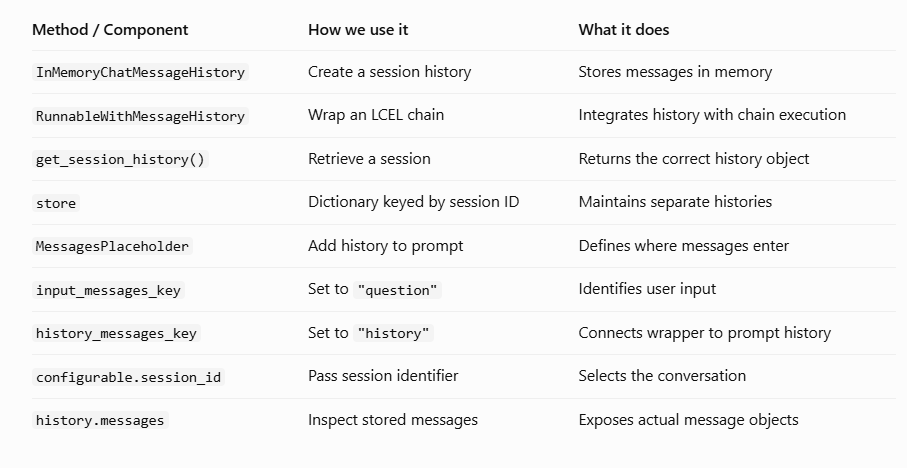